In [1]:

# Day 50: Capstone Model Optimization
# Step 1: Import required libraries

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Step 2: Load the customer-risk dataset

df = pd.read_csv("day41_customer_risk_scores.csv")

print("Dataset shape:", df.shape)
print("\nMissing values per column:")
print(df.isnull().sum())

print("\nRisk-level distribution:")
print(df["Risk_Level"].value_counts())


Dataset shape: (793, 12)

Missing values per column:
Customer ID               0
Total_Sales               0
Total_Orders              0
Last_Order_Date           0
First_Order_Date          0
Average_Order_Value       0
Customer_Lifetime_Days    0
Recency_Days              0
Purchase_Frequency        0
Estimated_CLV             0
Risk_Score                0
Risk_Level                0
dtype: int64

Risk-level distribution:
Risk_Level
Low Risk       265
High Risk      264
Medium Risk    264
Name: count, dtype: int64


In [3]:

# Step 3: Prepare features and target

feature_columns = [
    "Total_Sales",
    "Total_Orders",
    "Average_Order_Value",
    "Customer_Lifetime_Days",
    "Recency_Days",
    "Purchase_Frequency",
    "Estimated_CLV"
]

X = df[feature_columns]
y = df["Risk_Level"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeatures used:")
print(feature_columns)


Feature matrix shape: (793, 7)
Target shape: (793,)

Features used:
['Total_Sales', 'Total_Orders', 'Average_Order_Value', 'Customer_Lifetime_Days', 'Recency_Days', 'Purchase_Frequency', 'Estimated_CLV']


In [4]:

# Step 4: Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 634
Testing records: 159


In [5]:

# Step 5: Train the baseline Random Forest model

baseline_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

baseline_model.fit(X_train, y_train)

# Predict risk categories for unseen test data
y_pred = baseline_model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("BASELINE MODEL PERFORMANCE")
print("-" * 35)
print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


BASELINE MODEL PERFORMANCE
-----------------------------------
Accuracy: 0.9245 (92.45%)

Classification Report:
              precision    recall  f1-score   support

   High Risk       0.95      0.98      0.96        53
    Low Risk       0.96      0.89      0.92        53
 Medium Risk       0.87      0.91      0.89        53

    accuracy                           0.92       159
   macro avg       0.93      0.92      0.92       159
weighted avg       0.93      0.92      0.92       159



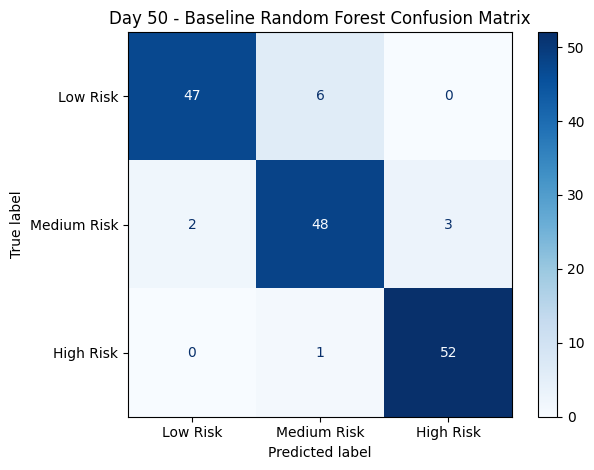

In [6]:

# Step 6: Visualize the baseline confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low Risk", "Medium Risk", "High Risk"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Day 50 - Baseline Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()


In [7]:

# Step 7: Compare multiple classification algorithms

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    )
}

comparison_results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    comparison_results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Test Macro F1": f1_score(
            y_test, test_pred, average="macro"
        )
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values(
    by="Test Macro F1", ascending=False
)

print(comparison_df.round(4).to_string(index=False))


              Model  Train Accuracy  Test Accuracy  Test Macro F1
Logistic Regression          0.9543         0.9497         0.9499
      Random Forest          1.0000         0.9245         0.9245
      Decision Tree          1.0000         0.9119         0.9110


In [8]:

# Step 8: Hyperparameter tuning with GridSearchCV

from sklearn.model_selection import GridSearchCV, StratifiedKFold

logistic_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=3000,
        random_state=42
    )
)

param_grid = {
    "logisticregression__C": [0.01, 0.1, 1, 10, 100],
    "logisticregression__solver": ["lbfgs"],
    "logisticregression__class_weight": [None, "balanced"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation macro F1:")
print(round(grid_search.best_score_, 4))

best_model = grid_search.best_estimator_
tuned_pred = best_model.predict(X_test)

print("\nTuned model test accuracy:")
print(round(accuracy_score(y_test, tuned_pred), 4))

print("\nTuned model test macro F1:")
print(round(f1_score(y_test, tuned_pred, average="macro"), 4))


Best parameters:
{'logisticregression__C': 100, 'logisticregression__class_weight': None, 'logisticregression__solver': 'lbfgs'}

Best cross-validation macro F1:
0.981

Tuned model test accuracy:
0.9748

Tuned model test macro F1:
0.9747


                       Model  Test Accuracy  Test Macro F1
Baseline Logistic Regression         0.9245         0.9245
   Tuned Logistic Regression         0.9748         0.9747


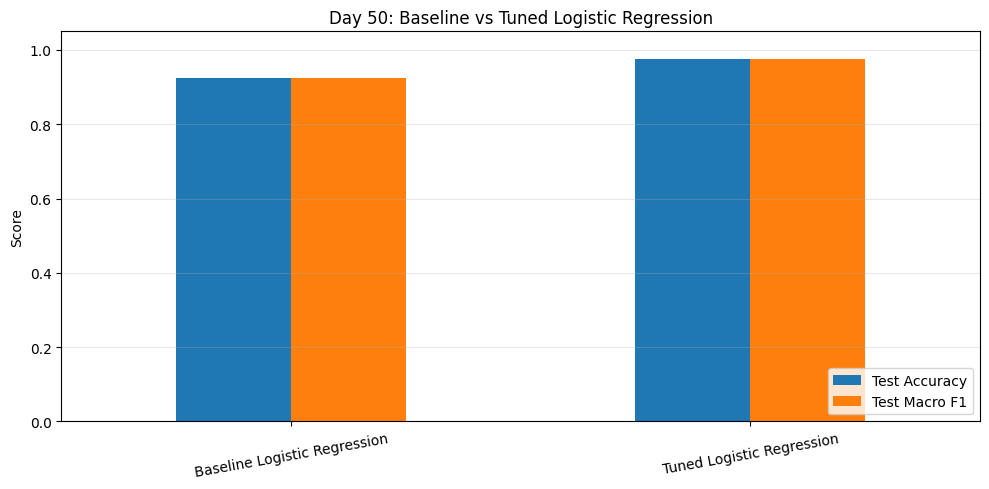

In [9]:

# Step 9: Compare baseline and tuned model performance

baseline_accuracy = accuracy_score(y_test, y_pred)
tuned_accuracy = accuracy_score(y_test, tuned_pred)

baseline_f1 = f1_score(
    y_test, y_pred, average="macro"
)

tuned_f1 = f1_score(
    y_test, tuned_pred, average="macro"
)

performance_df = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Tuned Logistic Regression"
    ],
    "Test Accuracy": [
        baseline_accuracy, tuned_accuracy
    ],
    "Test Macro F1": [
        baseline_f1, tuned_f1
    ]
})

print(performance_df.round(4).to_string(index=False))

ax = performance_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1.05),
    rot=10
)

ax.set_title("Day 50: Baseline vs Tuned Logistic Regression")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "day50_model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [10]:

# Step 10: Analyze overfitting and generalization

tuned_train_pred = best_model.predict(X_train)
tuned_test_pred = best_model.predict(X_test)

train_accuracy = accuracy_score(y_train, tuned_train_pred)
test_accuracy = accuracy_score(y_test, tuned_test_pred)

accuracy_gap = train_accuracy - test_accuracy

print("TUNED MODEL GENERALIZATION CHECK")
print("-" * 40)
print(f"Training accuracy: {train_accuracy:.4f}")
print(f"Testing accuracy:  {test_accuracy:.4f}")
print(f"Train-test gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("\nObservation: Large train-test gap; investigate overfitting.")
elif accuracy_gap > 0.03:
    print("\nObservation: Moderate train-test gap; continue validation.")
else:
    print("\nObservation: Small train-test gap; encouraging generalization.")


TUNED MODEL GENERALIZATION CHECK
----------------------------------------
Training accuracy: 0.9937
Testing accuracy:  0.9748
Train-test gap:    0.0188

Observation: Small train-test gap; encouraging generalization.


In [11]:

# Step 11: Save the model comparison report

comparison_df.to_csv(
    "day50_model_comparison_report.csv",
    index=False
)

performance_df.to_csv(
    "day50_baseline_vs_tuned.csv",
    index=False
)

print("Saved model comparison reports:")
print("- day50_model_comparison_report.csv")
print("- day50_baseline_vs_tuned.csv")

print("\nFinal model comparison:")
print(comparison_df.round(4).to_string(index=False))


Saved model comparison reports:
- day50_model_comparison_report.csv
- day50_baseline_vs_tuned.csv

Final model comparison:
              Model  Train Accuracy  Test Accuracy  Test Macro F1
Logistic Regression          0.9543         0.9497         0.9499
      Random Forest          1.0000         0.9245         0.9245
      Decision Tree          1.0000         0.9119         0.9110
